# Fill-curve planning — walkthrough

This notebook rebuilds, on **synthetic data**, the core ideas behind a fill-curve planning product:
historical benchmarks → target curves → projections → gap decomposition → outreach sizing → gross-vs-net → quality gates.

Every number below is generated by `curvekit.synth` — nothing comes from a real company.

In [1]:
import sys; sys.path.insert(0, "../src")   # run from the notebooks/ folder
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from curvekit import synth, curves, strategies, gross_net, quality

pd.set_option("display.width", 160)
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SEG_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed categorical order
STATUS = {"on pace": "#0ca30c", "watch": "#fab219", "behind": "#d03b3b"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK})

deps = synth.make_sessions(n_hist=240, n_future=24, seed=19)
bk = synth.make_appointments(deps, seed=23)
print(f"{(~deps.is_future).sum()} historical sessions, {deps.is_future.sum()} open for appointment, {len(bk):,} daily rows")
deps.groupby("segment").size().rename("sessions").to_frame()

240 historical sessions, 24 open for appointment, 92,780 daily rows


,sessions
segment,
local / flu season / one-day,66
local / off-season / one-day,66
regional / flu season / multi-day,66
regional / off-season / multi-day,66


## 1. Historical benchmarks and target curves
For each segment we look at how full past sessions were at every point in the appointment window.
The **target curve** is the 60th percentile of that history — ambitious, but something the segment has actually achieved.
Targets are forced to be non-decreasing toward session.

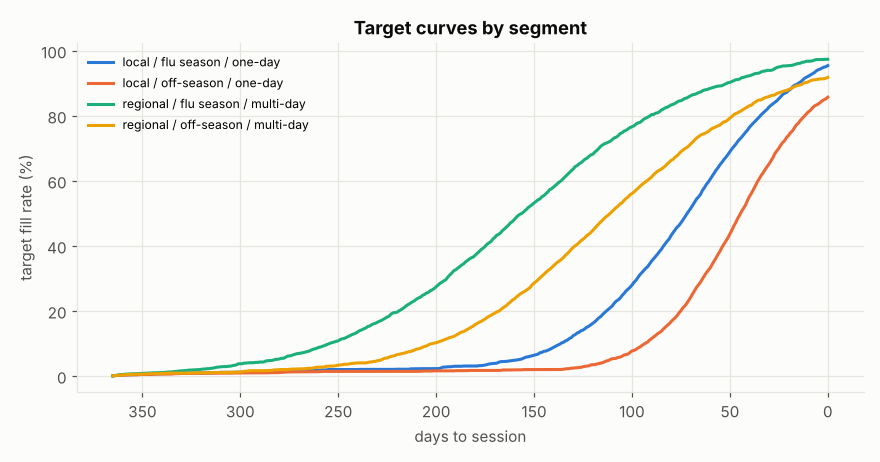

In [2]:
profiles = curves.historical_profiles(bk, deps)
cv = curves.segment_curves(profiles, target_pct=60)

fig, ax = plt.subplots(figsize=(8, 4.2))
for color, (seg, g) in zip(SEG_COLORS, cv.groupby("segment", sort=False)):
    g = g.sort_values("days_out")
    ax.plot(g.days_out, g.target_fill * 100, color=color, lw=2, label=seg)
ax.invert_xaxis(); ax.set_xlabel("days to session"); ax.set_ylabel("target fill rate (%)")
ax.set_title("Target curves by segment"); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("../figures/target_curves.png", dpi=150); plt.show()

## 2. Where is each open session, and where will it land?
**Projection** = appointments today ÷ share of final appointments usually on the books at this point (the pickup method),
blended with the segment's typical outcome while the appointment window is young (little data → lean on history).
A volatility band (± 1 standard deviation of that share) gives a low/high range.

The gap is split into pieces an operations team can act on:
- `pace_gap_today` — how far behind today's target we are
- `gap_to_target` — appointments still needed at session to hit the target
- `gap_to_full` — room left before the session is completely full

In [3]:
pos = curves.current_position(bk, deps)
plan = curves.project_and_decompose(pos, cv, z=1.0)
plan[["session_id", "segment", "capacity", "days_out_today", "net_appointments", "projected_final",
      "target_final", "pace_gap_today", "gap_to_target", "gap_to_full", "status"]].head(10)

,session_id,segment,capacity,days_out_today,net_appointments,projected_final,target_final,pace_gap_today,gap_to_target,gap_to_full,status
0,S0240,regional / flu season / multi-day,1200,150,578,1090.0,1169.0,61.0,79.0,110.0,behind
1,S0241,regional / off-season / multi-day,1200,141,220,640.0,1102.0,180.0,462.0,560.0,behind
2,S0242,local / flu season / one-day,2400,52,1556,2230.0,2291.0,59.0,61.0,170.0,watch
3,S0243,local / off-season / one-day,2400,144,1,1916.0,2058.0,48.0,142.0,484.0,behind
4,S0244,regional / flu season / multi-day,3000,214,710,3000.0,2922.0,-47.0,0.0,0.0,on pace
5,S0245,regional / off-season / multi-day,1800,238,139,1800.0,1653.0,-66.0,0.0,0.0,on pace
6,S0246,local / flu season / one-day,2400,96,651,2083.0,2291.0,96.0,208.0,317.0,behind
7,S0247,local / off-season / one-day,1200,149,5,972.0,1029.0,19.0,57.0,228.0,watch
8,S0248,regional / flu season / multi-day,1800,105,1425,1800.0,1753.0,-78.0,0.0,0.0,on pace
9,S0249,regional / off-season / multi-day,2400,77,1685,2271.0,2204.0,-60.0,0.0,129.0,on pace


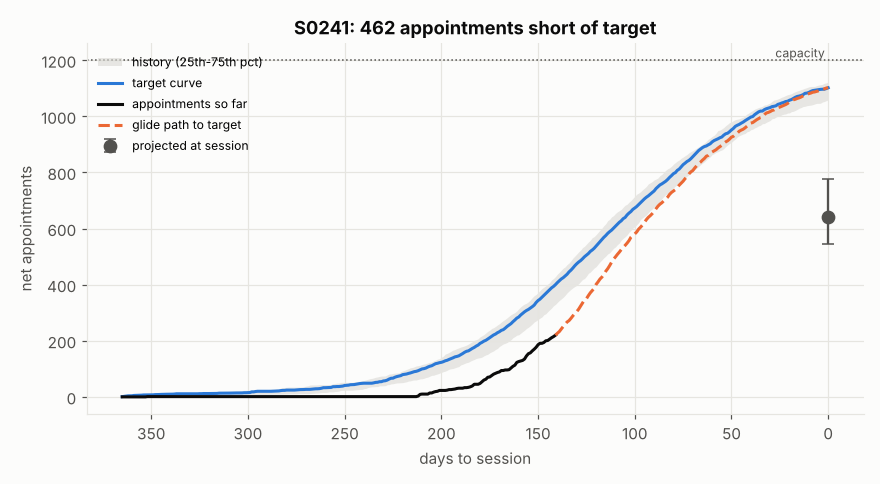

In [4]:
row = plan.sort_values("gap_to_target").iloc[-1]          # the session furthest behind
seg = cv[cv.segment == row.segment].sort_values("days_out")
hist = profiles[profiles.segment == row.segment]
band = hist.groupby("days_out").fill.quantile([0.25, 0.75]).unstack() * row.capacity
actual = bk[bk.session_id == row.session_id]
path = curves.glide_path(row, cv, goal=row.target_final)

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.fill_between(band.index, band[0.25], band[0.75], color="#d9d8d3", alpha=0.6, lw=0, label="history (25th-75th pct)")
ax.plot(seg.days_out, seg.target_fill * row.capacity, color="#2a78d6", lw=2, label="target curve")
ax.plot(actual.days_out, actual.net_appointments, color=INK, lw=2, label="appointments so far")
ax.plot(path.days_out, path.glide_path, color="#eb6834", lw=2, ls="--", label="glide path to target")
ax.errorbar([0], [row.projected_final], yerr=[[row.projected_final - row.projected_low], [row.projected_high - row.projected_final]],
            fmt="o", color=MUTED, ms=8, capsize=4, label="projected at session")
ax.axhline(row.capacity, color=MUTED, lw=1, ls=":"); ax.text(0, row.capacity, "capacity ", ha="right", va="bottom", color=MUTED, fontsize=8)
ax.invert_xaxis(); ax.set_xlabel("days to session"); ax.set_ylabel("net appointments")
ax.set_title(f"{row.session_id}: {int(row.gap_to_target)} appointments short of target")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("../figures/session_glide_path.png", dpi=150); plt.show()

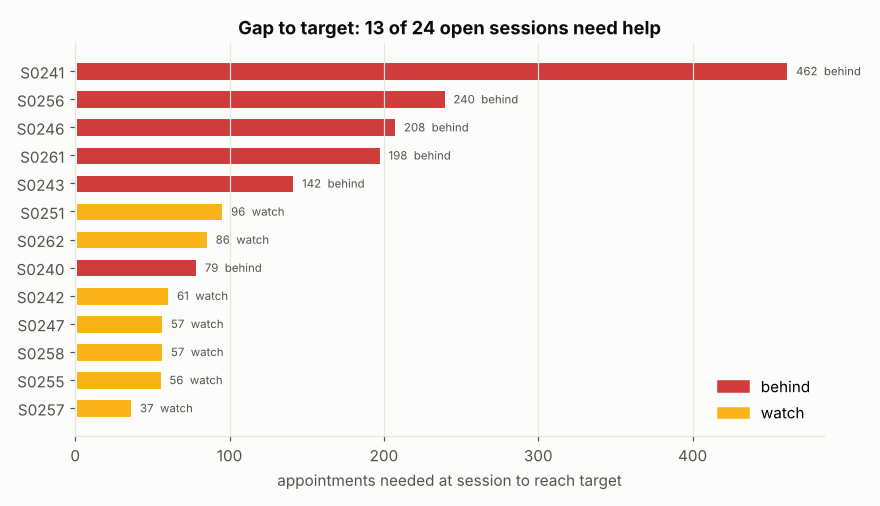

,sessions
status,
on pace,10
watch,8
behind,6


In [5]:
p = plan[plan.gap_to_target > 0].sort_values("gap_to_target")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(p.session_id, p.gap_to_target, color=[STATUS[s] for s in p.status], height=0.7, edgecolor=SURFACE, linewidth=2)
for y, (v, s) in enumerate(zip(p.gap_to_target, p.status)):
    if v > 0: ax.text(v + 5, y, f"{int(v)}  {s}", va="center", fontsize=7.5, color=MUTED)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=STATUS[k], label=k) for k in ["behind", "watch"]], frameon=False, loc="lower right")
ax.set_xlabel("appointments needed at session to reach target")
ax.set_title(f"Gap to target: {len(p)} of {len(plan)} open sessions need help")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("../figures/gap_to_target.png", dpi=150); plt.show()
plan.status.value_counts().rename("sessions").to_frame()

## 3. Sizing outreach campaigns — and when to run them
Routine scheduling alone may not close the gap. Sessions that are **eligible** (gap ≥ 25 appointments and ≥ 1 % of capacity,
benchmark backed by ≥ 20 past sessions) get an outreach plan. Two strategies are compared:

| Strategy | How it spreads the gap | Trade-off |
|---|---|---|
| **baseline** | in proportion to how appointments normally arrive | stable, low risk — the default |
| **milestones** | cumulative checkpoints (50 % by ¼ of the remaining time, 80 % by ½) | closes faster, more execution risk |

A **control-total reconciliation** confirms every plan adds up exactly to its gap.

eligible sessions: 13 | reconciliation ok: True


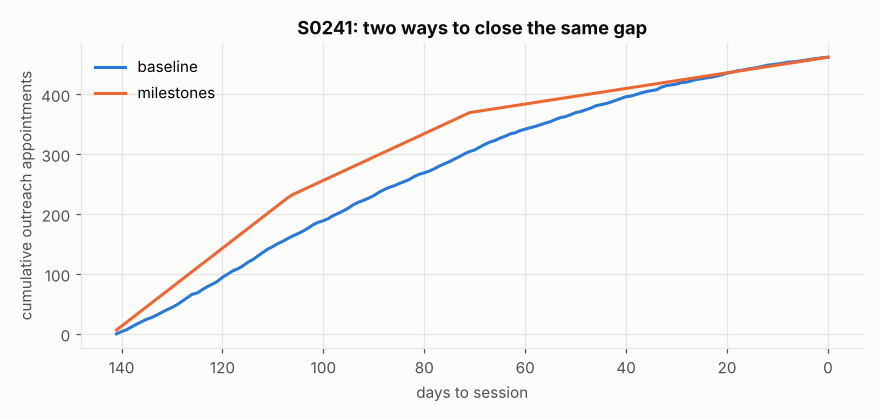

In [6]:
base = strategies.build_outreach_plan(plan, cv, "baseline")
mile = strategies.build_outreach_plan(plan, cv, "milestones")
print("eligible sessions:", base.session_id.nunique(), "| reconciliation ok:",
      strategies.reconcile(plan, base).ok.all() and strategies.reconcile(plan, mile).ok.all())

one = row.session_id
fig, ax = plt.subplots(figsize=(8, 3.8))
for color, (name, a) in zip(["#2a78d6", "#eb6834"], [("baseline", base), ("milestones", mile)]):
    a = a[a.session_id == one].sort_values("days_out", ascending=False)
    ax.plot(a.days_out, a.outreach_units.cumsum(), color=color, lw=2, label=name)
ax.invert_xaxis(); ax.set_xlabel("days to session"); ax.set_ylabel("cumulative outreach appointments")
ax.set_title(f"{one}: two ways to close the same gap"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("../figures/outreach_strategies.png", dpi=150); plt.show()

## 4. Gross vs. net
Some appointments on the books today will cancel. The share that survives to session depends on how far out we are,
so gross appointments are converted to an expected net figure before comparing them with targets.

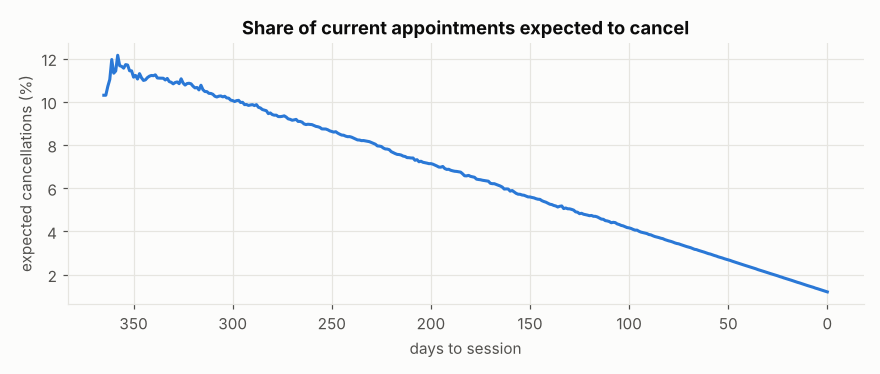

,session_id,segment,days_out_today,gross_appointments,net_appointments,cancel_rate,expected_net_from_gross,gross_net_gap
0,S0240,regional / flu season / multi-day,150,612,578,0.056450,577.0,35.0
1,S0241,regional / off-season / multi-day,141,232,220,0.053625,220.0,12.0
2,S0242,local / flu season / one-day,52,1600,1556,0.027342,1556.0,44.0
3,S0243,local / off-season / one-day,144,1,1,0.052864,1.0,0.0
4,S0244,regional / flu season / multi-day,214,767,710,0.075206,709.0,58.0
5,S0245,regional / off-season / multi-day,238,152,139,0.082522,139.0,13.0


In [7]:
prof = gross_net.cancellation_profile(cv)
gn = gross_net.gross_to_net(pos, prof)
avg = prof.groupby("days_out").cancel_rate.mean()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(avg.index, avg * 100, color="#2a78d6", lw=2)
ax.invert_xaxis(); ax.set_xlabel("days to session"); ax.set_ylabel("expected cancellations (%)")
ax.set_title("Share of current appointments expected to cancel")
fig.tight_layout(); fig.savefig("../figures/cancellation_profile.png", dpi=150); plt.show()
gn.head(6)

## 5. Quality gates before anything is published
Checks run on every build; a **validation gate** compares the new projections with the last published run and blocks
the publish if anything moved more than 5 %. Outputs are copied to history (**snapshot-first**) before being overwritten.

In [8]:
print(quality.run_checks(bk, deps, plan).to_string(index=False))
moved = plan.assign(projected_final=plan.projected_final * np.where(plan.index % 5 == 0, 1.12, 1.0))
ok, breaches = quality.validation_gate(moved, plan, "session_id", "projected_final", 0.05)
print(f"\npublish allowed: {ok} ({len(breaches)} sessions moved more than 5%)")

                                 check  passed             detail
    no duplicate session/days_out rows    True                   
                     no missing values    True                   
       appointments within 0..capacity    True                   
               net never exceeds gross    True                   
cumulative appointments never decrease    True  0 sessions failed
projection outliers flagged for review    True 0 sessions flagged

publish allowed: False (5 sessions moved more than 5%)


## Takeaways
- Benchmarks come from history, targets are realistic, and every projection carries a range.
- Gaps are broken into *today*, *at session* and *to full* — each maps to a different action.
- Outreach plans always reconcile to the gap; strategy choice is a visible, testable trade-off.
- Nothing goes live without passing quality checks, and every overwrite is recoverable.